# **PROJECT 1: TOXIC COMMENTS CLASSIFICATION**

## **Data Importation**

In [2]:
import pandas as pd

data_toxic = pd.read_csv(
    r"train.csv",
    engine="python",
    on_bad_lines="warn"
)

print(data_toxic.tail(5))

                      id                                       comment_text  \
159566  ffe987279560d7ff  ":::::And for the second time of asking, when ...   
159567  ffea4adeee384e90  You should be ashamed of yourself \n\nThat is ...   
159568  ffee36eab5c267c9  Spitzer \n\nUmm, theres no actual article for ...   
159569  fff125370e4aaaf3  And it looks like it was actually you who put ...   
159570  fff46fc426af1f9a  "\nAnd ... I really don't think you understand...   

        toxic  severe_toxic  obscene  threat  insult  identity_hate  
159566      0             0        0       0       0              0  
159567      0             0        0       0       0              0  
159568      0             0        0       0       0              0  
159569      0             0        0       0       0              0  
159570      0             0        0       0       0              0  


## **Data exploration**

In [3]:
print(data_toxic.shape)
print(data_toxic.columns)
print(data_toxic["toxic"].value_counts())

(159571, 8)
Index(['id', 'comment_text', 'toxic', 'severe_toxic', 'obscene', 'threat',
       'insult', 'identity_hate'],
      dtype='object')
toxic
0    144277
1     15294
Name: count, dtype: int64


This dataset contains 158,571 comments and 8 columns. The column we are interested in is `toxic`, which is coded 0 for non-toxic comments and 1 for toxic comments.

There are therefore significantly fewer toxic comments in the dataset, with 15,294 toxic comments compared to 144,277 non-toxic comments.

In [4]:
print(data_toxic["comment_text"].isnull().sum())
print(data_toxic["toxic"].isnull().sum())

0
0


There is none missing value

In [5]:
print(data_toxic["toxic"].value_counts(normalize=True))

toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64


## **PART 1 : TEXT PREPROCESSING**

We import the NLP tools

In [6]:
import pandas as pd
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\damil\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\damil\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\damil\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


STEP 1 - TOKENISATION

In [7]:
# Step 1: Tokenization (lowercase + word split)

data_toxic["tokens"] = data_toxic["comment_text"].apply(
    lambda x: word_tokenize(str(x).lower())
)

data_toxic[["comment_text", "tokens"]].head(5)

,comment_text,tokens
0,Explanation\nWhy the edits made under my usern...,"[explanation, why, the, edits, made, under, my..."
1,D'aww! He matches this background colour I'm s...,"[d'aww, !, he, matches, this, background, colo..."
2,"Hey man, I'm really not trying to edit war. It...","[hey, man, ,, i, 'm, really, not, trying, to, ..."
3,"""\nMore\nI can't make any real suggestions on ...","[``, more, i, ca, n't, make, any, real, sugges..."
4,"You, sir, are my hero. Any chance you remember...","[you, ,, sir, ,, are, my, hero, ., any, chance..."


STEP 2 - REMOVE STOPWORDS

In [8]:
# Step 2: Remove stopwords

stop_words = set(stopwords.words('english'))

# Keep negations + "you" because it may be informative for toxicity
stop_words -= {"not", "no", "nor", "n't", "you","neither"}

data_toxic["tokens_nostop"] = data_toxic["tokens"].apply(
    lambda toks: [t for t in toks if t not in stop_words]
)

data_toxic[["tokens", "tokens_nostop"]].head(5)

,tokens,tokens_nostop
0,"[explanation, why, the, edits, made, under, my...","[explanation, edits, made, username, hardcore,..."
1,"[d'aww, !, he, matches, this, background, colo...","[d'aww, !, matches, background, colour, 'm, se..."
2,"[hey, man, ,, i, 'm, really, not, trying, to, ...","[hey, man, ,, 'm, really, not, trying, edit, w..."
3,"[``, more, i, ca, n't, make, any, real, sugges...","[``, ca, n't, make, real, suggestions, improve..."
4,"[you, ,, sir, ,, are, my, hero, ., any, chance...","[you, ,, sir, ,, hero, ., chance, you, remembe..."


We add "you" for expressions like "you gay". For example, it is quite difficult to know if the word gay employed alone is in a context of toxicity or not. Such word seems more like toxic comment employed with "you". 

STEP 3 - REMOVE SPECIAL CHARACTERS

Dans la première partie de ce code, nous avons fait un code qui permet de remplacer les caractères spéciaux à l'intérieur des mots par des lettres afin de retrouver la forme correcte de ces mots. Ex:c*nt => cunt. Notre liste est composée des mots qui reviennent le plus et n'est pas exhaustive.
Après cela, nous supprimons tous les mots qui sont des carctères spéciaux sauf les "!", "0", "1", "@" et "***"  which are frequently used in toxic words such as: idi0t, 1d1ot, !d!ot et que nous aurions pu ne pas couvrir avec notre liste de mots.

In [9]:
# Step 3: Special-character cleaning

import re

def normalize_censored_profanity(token: str) -> str:
    """Reduce common obfuscated profanity to a readable form."""

    replacements = [
        (r'\bf\*+\*?ck\b', 'fuck'),
        (r'\bfu\*+\*?k\b', 'fuck'),
        (r'\bf\*+\*?cked\b', 'fucked'),
        (r'\bf\*+\*?cking\b', 'fucking'),
        (r"\bf\*{2}in(?:')?\b", 'fuckin'),
        (r'\bf\*+\*?cker\b', 'fucker'),
        (r'\bbvllsh(?:1|!|i)?t\b', 'bullshit'),
        (r'\bbullsh(?:1|!|i)?t\b', 'bullshit'),
        (r'\bsh\*+!*\*t\b', 'shit'),
        (r'\bb\*+!*\*tch\b', 'bitch'),
        (r'\ba\*+\*?hole\b', 'asshole'),
        (r'\bd\*+!*\*ck\b', 'dick'),
        (r'\bc\*+\*?nt\b', 'cunt'),
        (r'\bfaggot\b', 'faggot'),
        (r'\bn\*+!*\*gger\b', 'nigger'),
    ]

    for pattern, replacement in replacements:
        token = re.sub(
            pattern,
            replacement,
            token,
            flags=re.IGNORECASE
        )

    return token


def clean_special_tokens(tokens):
    cleaned = []

    for t in tokens:

        # 1. Normalize censored/obfuscated profanity
        t = normalize_censored_profanity(t)

        # 2. Remove unwanted special characters
        # Keep letters, 0, 1, !, @, *, and apostrophes
        t = re.sub(r"[^a-z01!@*']", '', t)

        # 3. Remove empty tokens
        if t:
            cleaned.append(t)

    return cleaned


data_toxic["tokens_cleaned"] = data_toxic["tokens_nostop"].apply(
    clean_special_tokens
)

data_toxic[["tokens_nostop", "tokens_cleaned"]].head(5)

,tokens_nostop,tokens_cleaned
0,"[explanation, edits, made, username, hardcore,...","[explanation, edits, made, username, hardcore,..."
1,"[d'aww, !, matches, background, colour, 'm, se...","[d'aww, !, matches, background, colour, 'm, se..."
2,"[hey, man, ,, 'm, really, not, trying, edit, w...","[hey, man, 'm, really, not, trying, edit, war,..."
3,"[``, ca, n't, make, real, suggestions, improve...","[ca, n't, make, real, suggestions, improvement..."
4,"[you, ,, sir, ,, hero, ., chance, you, remembe...","[you, sir, hero, chance, you, remember, page, 's]"


STEP 4 - STEMMING

In [10]:
import sys

# Increase the recursion limit even further
sys.setrecursionlimit(10000)

# Step 4: Stemming

data_toxic["tokens_stemmed"] = data_toxic["tokens_cleaned"].apply(
    lambda toks: [stemmer.stem(t) for t in toks]
)

data_toxic[["tokens_cleaned", "tokens_stemmed"]].head(5)

,tokens_cleaned,tokens_stemmed
0,"[explanation, edits, made, username, hardcore,...","[explan, edit, made, usernam, hardcor, metalli..."
1,"[d'aww, !, matches, background, colour, 'm, se...","[d'aww, !, match, background, colour, 'm, seem..."
2,"[hey, man, 'm, really, not, trying, edit, war,...","[hey, man, 'm, realli, not, tri, edit, war, 's..."
3,"[ca, n't, make, real, suggestions, improvement...","[ca, n't, make, real, suggest, improv, wonder,..."
4,"[you, sir, hero, chance, you, remember, page, 's]","[you, sir, hero, chanc, you, rememb, page, 's]"


In [11]:
# Rebuild processed text

data_toxic["processed_text"] = data_toxic["tokens_stemmed"].apply(
    lambda toks: " ".join(toks)
)

data_toxic[["comment_text", "processed_text"]].head(5)

,comment_text,processed_text
0,Explanation\nWhy the edits made under my usern...,explan edit made usernam hardcor metallica fan...
1,D'aww! He matches this background colour I'm s...,d'aww ! match background colour 'm seemingli s...
2,"Hey man, I'm really not trying to edit war. It...",hey man 'm realli not tri edit war 's guy cons...
3,"""\nMore\nI can't make any real suggestions on ...",ca n't make real suggest improv wonder section...
4,"You, sir, are my hero. Any chance you remember...",you sir hero chanc you rememb page 's


#### **PART 1 ANSWERS**

#### 1. Which preprocessing step would you skip here, and why?

We skipped the removal of HTML characters because there is no HTML in the comments.

#### 2. Which stopwords would you keep in this task, and why?

We keep **"not", "no", "nor", "n't", "you", and "neither"** because these stopwords are frequently used in toxic expressions.

For example:

* *"You are not smart."*
* *"You are neither welcome here nor wanted by anyone."*

#### 3. Propose one preprocessing tweak that might help toxic detection and that we have not covered.

The tweak we propose is to create a piece of code that replaces special characters inside words with letters in order to recover the correct form of these words.

For example:

**c*nt → cunt**

Our list consists of frequently occurring words and is not exhaustive.


## **PART 2 - FEATURE ENGINEERING**

Bag of words

In [35]:
from sklearn.feature_extraction.text import CountVectorizer

# Bag of Words - unigrams
vectorizer_bow = CountVectorizer()

X_bow = vectorizer_bow.fit_transform(
    data_toxic["processed_text"]
)

print("Shape of document-term matrix:", X_bow.shape)

Shape of document-term matrix: (159571, 171607)


In [36]:
df_bow_preview = pd.DataFrame(X_bow[9:10].toarray(), columns=vectorizer_bow.get_feature_names_out())
pd.set_option("display.max_colwidth", None)
print(data_toxic["processed_text"].iloc[0])
# Show only the columns where counts are zero
print(df_bow_preview.loc[:, (df_bow_preview == 0).any(axis=0)])
# Show only the columns where counts are non-zero
print(df_bow_preview.loc[:, (df_bow_preview != 0).any(axis=0)])
# Show how many times the word "abandon" appears
int(df_bow_preview["fuck"].iloc[0])

explan edit made usernam hardcor metallica fan revert n't vandal closur ga vote new york doll fac pleas n't remov templat talk page sinc 'm retir now0
   00  000  0000  00000  000000  0000000  00000000  000000000  0000000000  \
0   0    0     0      0       0        0         0          0           0   

   0000000000000000  ...  zzz  zzzz  zzzzz  zzzzzzz  zzzzzzzzzzzzzzzzz  \
0                 0  ...    0     0      0        0                  0   

   zzzzzzzzzzzzzzzzzzzzz  zzzzzzzzzzzzzzzzzzzzzzzzzzzzzz  \
0                      0                               0   

   zzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzz  \
0                                                          0   

   zzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzzz  \
0                                                                                                                                          

0

In [38]:
# Bag of Words with unigrams + bigrams

vectorizer_ngram = CountVectorizer(ngram_range=(1, 2))

X_ngram = vectorizer_ngram.fit_transform(
    data_toxic["processed_text"]
)

print("Shape of document-term matrix:", X_ngram.shape)

Shape of document-term matrix: (159571, 2411180)


#### **PART 2 ANSWER**

The bigram representation is most important because it take into account the expressions with one word and it permits to consider expressions which use more than one word, in our specific case, it means two words.

## **PART 3 - MODELING**

Step 1 — Train / Test Split

In [39]:
from sklearn.model_selection import train_test_split

# Target variable
y = data_toxic["toxic"]

# Text variable
X_text = data_toxic["processed_text"]

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X_ngram,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (127656, 2411180)
Test size: (31915, 2411180)


In [40]:
print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))


Train target distribution:
toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64

Test target distribution:
toxic
0    0.904152
1    0.095848
Name: proportion, dtype: float64


The toxic class is a minority. stratify=y allows you to roughly keep the same proportion of toxic and non-toxic comments in the training and test sets.

Step 3 — Logistic Regression

In [41]:
# Step 3: Logistic Regression

from sklearn.linear_model import LogisticRegression

clf_lr = LogisticRegression(max_iter=400)
clf_lr.fit(X_train, y_train)

# Store predictions (for Part 4 evaluation)
y_pred_test_lr = clf_lr.predict(X_test)

Step 4: Linear SVM

In [42]:
# Step 4: Linear SVM
from sklearn.svm import LinearSVC

clf_svm = LinearSVC()

clf_svm.fit(X_train, y_train)

y_pred_test_svm = clf_svm.predict(X_test)

c:\Users\kodja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


Step 5: Random Forest

In [43]:
from sklearn.ensemble import RandomForestClassifier

clf_rf = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

clf_rf.fit(X_train, y_train)

# Store predictions (for Part 4 evaluation)
y_pred_test_rf = clf_rf.predict(X_test)

STEP 4 — TOXIC KEYWORD BASELINE

In [ ]:
X_text = data_toxic["processed_text"]
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=42, stratify=y
)

# Minimal keyword toxicity baseline
TOXIC = {
    "!", "@", "1", "0", "*", "nt", "not wanted", "no brain",
    "no intelligence", "not smart", "not normal", "bad", "terrible",
    "awful", "boring", "worst", "hate", "poor", "waste", "disappoint",
    "dull", "mess", "ridiculous", "horrible", "fuck", "cock", "suck",
    "pathetic", "stupid", "idiot", "fail", "ruin", "fake", "shit",
    "moron", "bitch", "asshol", "retard", "dumb", "kill", "die",
    "conts", "are gay", "you gay", "nigger", "cunt", "faggot",
    "bullshit", "stupid idiot", "dumb idiot", "fucking idiot",
    "fucking stupid", "stupid person", "pathetic loser",
    "complete idiot", "total idiot", "absolute idiot",
    "disgusting person", "horrible person", "terrible person",
    "worthless person", "piece shit", "piece trash", "shut up",
    "go away", "get lost", "hate you", "kill yourself", "you suck",
    "you idiot", "you stupid", "you moron", "you loser", "you pathetic"
}

def keyword_rule(text: str) -> int:
    toks = text.split()
    toxic = sum(1 for w in toks if w in TOXIC)
    return int(toxic > 0)

# Predictions (store for Part 4 evaluation)
y_pred_train_keyword = [keyword_rule(t) for t in X_train_text]
y_pred_test_keyword = [keyword_rule(t) for t in X_test_text]


#### **PART 3 ANSWER**

We choosed "!","@","1","0","*" as toxic words because most of the time they are contained in toxic words and expressions.
We choosed "nt","not wanted","no brain","no intelligence","not smart","not normal" because they are toxic expressions based on negative words.
The rest of expressions are basically toxics.

## **PART 4: EVALUATION**


In [45]:
# Evaluating the baseline

from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

print("Keyword baseline — classification report")
print(classification_report(y_test, y_pred_test_keyword, target_names=["neg","pos"]))

cm_kw = confusion_matrix(y_test, y_pred_test_keyword)
pd.DataFrame(cm_kw, index=["true_neg","true_pos"], columns=["pred_neg","pred_pos"])


Keyword baseline — classification report
              precision    recall  f1-score   support

         neg       0.96      0.71      0.82     28856
         pos       0.21      0.72      0.32      3059

    accuracy                           0.71     31915
   macro avg       0.58      0.71      0.57     31915
weighted avg       0.89      0.71      0.77     31915



,pred_neg,pred_pos
true_neg,20530,8326
true_pos,869,2190


In [46]:
# Evaluating the machine learning approach (Logistic Regression model)

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

clf_lr = LogisticRegression(max_iter=400)
clf_lr.fit(X_train, y_train)

y_pred_test_lr = clf_lr.predict(X_test)

print("Ngram + Logistic Regression — classification report")
print(classification_report(y_test, y_pred_test_lr, target_names=["neg", "pos"]))

cm_lr = confusion_matrix(y_test, y_pred_test_lr)

pd.DataFrame(
    cm_lr,
    index=["true_neg", "true_pos"],
    columns=["pred_neg", "pred_pos"]
)

Ngram + Logistic Regression — classification report
              precision    recall  f1-score   support

         neg       0.97      0.99      0.98     28856
         pos       0.88      0.69      0.77      3059

    accuracy                           0.96     31915
   macro avg       0.92      0.84      0.88     31915
weighted avg       0.96      0.96      0.96     31915



,pred_neg,pred_pos
true_neg,28557,299
true_pos,938,2121


In [47]:
# Evaluating the machine learning approach (SVM model)
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import LinearSVC

clf_svm = LinearSVC()
clf_svm.fit(X_train, y_train)

y_pred_test_svm = clf_svm.predict(X_test)

print("Ngram + LinearSVC — classification report")
print(classification_report(y_test, y_pred_test_svm, target_names=["neg","pos"]))

cm_svm = confusion_matrix(y_test, y_pred_test_svm)
pd.DataFrame(cm_svm, index=["true_neg","true_pos"], columns=["pred_neg","pred_pos"])


Ngram + LinearSVC — classification report
              precision    recall  f1-score   support

         neg       0.97      0.99      0.98     28856
         pos       0.84      0.73      0.78      3059

    accuracy                           0.96     31915
   macro avg       0.91      0.86      0.88     31915
weighted avg       0.96      0.96      0.96     31915



c:\Users\kodja\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:1298: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,pred_neg,pred_pos
true_neg,28424,432
true_pos,819,2240


In [48]:
# Evaluating the machine learning approach (Random Forest model)
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier

clf_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

clf_rf.fit(X_train, y_train)

y_pred_test_rf = clf_rf.predict(X_test)

print("TF-IDF + Random Forest — classification report")
print(classification_report(y_test, y_pred_test_rf, target_names=["neg", "pos"]))

cm_rf = confusion_matrix(y_test, y_pred_test_rf)

pd.DataFrame(
    cm_rf,
    index=["true_neg", "true_pos"],
    columns=["pred_neg", "pred_pos"]
)

TF-IDF + Random Forest — classification report
              precision    recall  f1-score   support

         neg       0.95      1.00      0.97     28856
         pos       0.96      0.48      0.64      3059

    accuracy                           0.95     31915
   macro avg       0.95      0.74      0.81     31915
weighted avg       0.95      0.95      0.94     31915



,pred_neg,pred_pos
true_neg,28791,65
true_pos,1594,1465


#### ROC curves and AUC of the three models

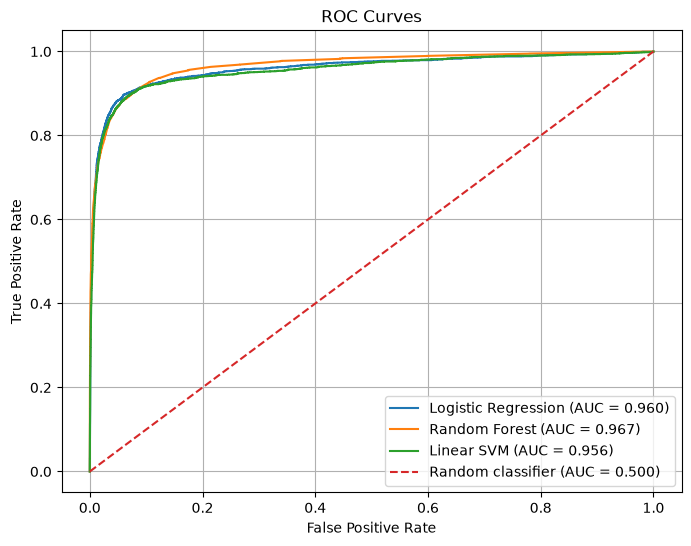

AUC scores:
Logistic Regression : 0.9596
Random Forest       : 0.9668
Linear SVM          : 0.9559


In [49]:
# we import packages

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Logistic Regression
y_score_lr = clf_lr.predict_proba(X_test)[:, 1]

# Random Forest
y_score_rf = clf_rf.predict_proba(X_test)[:, 1]

# Linear SVM
y_score_svm = clf_svm.decision_function(X_test)

# curves calculations

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_score_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_score_rf)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)

# AUC calculation

auc_lr = roc_auc_score(y_test, y_score_lr)
auc_rf = roc_auc_score(y_test, y_score_rf)
auc_svm = roc_auc_score(y_test, y_score_svm)

# ROC curve plot

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f"Logistic Regression (AUC = {auc_lr:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    fpr_svm,
    tpr_svm,
    label=f"Linear SVM (AUC = {auc_svm:.3f})"
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC = 0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")

plt.legend(loc="lower right")
plt.grid(True)
plt.show()

# To display AUC values

print("AUC scores:")
print(f"Logistic Regression : {auc_lr:.4f}")
print(f"Random Forest       : {auc_rf:.4f}")
print(f"Linear SVM          : {auc_svm:.4f}")

#### **PART 5 ANSWERS**

#### 1- Which metric should matter most: accuracy, precision, or recall?

It is certainly not accuracy, because the distribution of the toxic variable is not balanced in our dataset.
For us, the metric that should matter most is precision, because Wikipedia does not want to take the risk of banning users who do not post toxic messages. In other words, Wikipedia would rather let some toxic messages go through than incorrectly flag non-toxic users and potentially ban them. The goal is therefore to minimize false positives, even if this means that some toxic comments may not be detected.

#### 2- Discuss the consequences of each error type (False positive and false negative). Who is harmed in each case (the commenter,other users, moderators, the platform?)

With a high proportion of false positives, many commenters could be banned by mistake. The commenters would therefore be affected, and other users might be discouraged from using the platform. However, the platform would be perceived as very secure.

With a high proportion of false negatives, many toxic commenters would pass through the filter without being detected. Some users might decide to leave the platform because they feel that it is not safe enough. The moderators and the platform could then be criticized for not detecting toxic comments.

#### 3-  Consider context: would your answer change if the model was used for automatic blocking versus as a moderator support tool?Why?

If the model is used for automatic blocking it is better to prioritize precision otherwise it will ban many people for no reason.
If the model is used as a moderator support tool, it is better to prioritize recall to ban the maximum of toxic commenter.

#### 4- Compare this trade-off to a real-world analogy such as COVID testing. How is moderation on Wikipedia similar or different?

In the case of COVID testing, it is better to prioritize recall. Otherwise, there would be a risk of many people being classified as negative even though they are actually infected. The risk would be too high. It is better to have a higher probability of classifying people who are not infected as positive than to incorrectly classify people who are actually infected as negative.